### 4. What is the most optimal skill to learn for Data Analysts?

### Methodology

1. Group skills to determine median salary and likelihood of being in job postings.
2. Visualize median salary vs. percentage of skill demand.
3. (Optional) Determine if certain technologies are more prevalent.

In [1]:
# Importing Libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(
    lambda x: ast.literal_eval(x) if pd.notna(x) else x
)

/opt/anaconda3/envs/python_course/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df_DA_India = df[(df['job_title_short']=='Data Analyst') & (df['job_country']== 'United States')].copy()

In [3]:
df_DA_India = df[
    (df['job_title_short'] == 'Data Analyst') &
    (df['job_country'] == 'India')
].copy()

df_DA_India = df_DA_India.dropna(subset=['salary_year_avg'])

df_DA_India_exploded = df_DA_India.explode('job_skills')

df_DA_India_exploded[['salary_year_avg', 'job_skills']].head(5)

,salary_year_avg,job_skills
11412,50400.0,python
11412,50400.0,sql
11412,50400.0,aws
11412,50400.0,azure
11412,50400.0,excel


In [16]:
df_DA_skills = df_DA_India_exploded.groupby('job_skills')['salary_year_avg'].agg(['count', 'median']).sort_values(by='count', ascending=False)

df_DA_skills = df_DA_skills.rename(columns={'count': 'skill_count', 'median': 'median_salary'})

DA_job_count = len(df_DA_India)

df_DA_skills['skill_percent'] = df_DA_skills['skill_count'] / DA_job_count * 100

skill_limit = 5

df_DA_skills_high_demand = df_DA_skills[df_DA_skills['skill_percent'] > skill_limit]

df_DA_skills_high_demand

,skill_count,median_salary,skill_percent
job_skills,,,
sql,46,96050.00,48.936170
excel,39,98500.00,41.489362
python,36,96050.00,38.297872
tableau,20,108087.50,21.276596
r,18,79200.00,19.148936
power bi,17,111175.00,18.085106
azure,15,93600.00,15.957447
aws,12,79200.00,12.765957
oracle,11,79200.00,11.702128


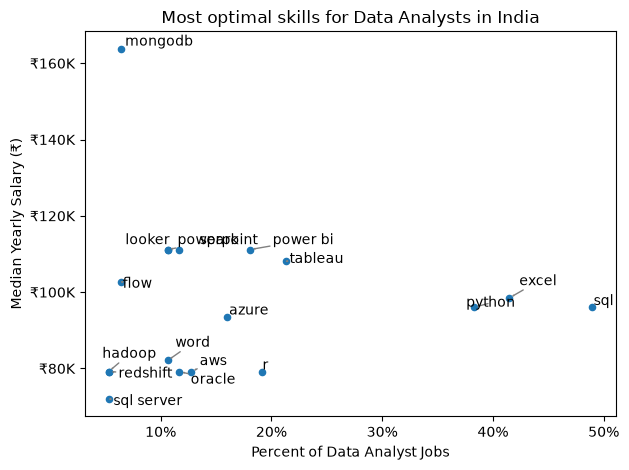

In [27]:
from adjustText import adjust_text
from matplotlib.ticker import PercentFormatter

df_DA_skills_high_demand.plot(kind='scatter', x='skill_percent', y='median_salary')

# Prepare texts for adjustText
texts = []
for i, txt in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(df_DA_skills_high_demand['skill_percent'].iloc[i], df_DA_skills_high_demand['median_salary'].iloc[i], txt))

# Adjust text to avoid overlap
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray'))

# Set axis labels, title, and legend
plt.xlabel('Percent of Data Analyst Jobs')
plt.ylabel('Median Yearly Salary (₹)')
plt.title('Most optimal skills for Data Analysts in India')

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'₹{int(y/1000)}K'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))

# Adjust layout and display plot
plt.tight_layout()
plt.show()

In [30]:
df['job_type_skills'].head(10)

0                                                  NaN
1    {'analyst_tools': ['power bi', 'tableau'], 'pr...
2    {'analyst_tools': ['dax'], 'cloud': ['azure'],...
3    {'cloud': ['aws'], 'libraries': ['tensorflow',...
4    {'cloud': ['oracle', 'aws'], 'other': ['ansibl...
5    {'cloud': ['gcp'], 'programming': ['python', '...
6    {'cloud': ['gcp', 'bigquery'], 'databases': ['...
7    {'cloud': ['gcp', 'azure', 'aws', 'bigquery', ...
8    {'analyst_tools': ['excel', 'powerpoint', 'pow...
9    {'analyst_tools': ['excel'], 'cloud': ['azure'...
Name: job_type_skills, dtype: str

In [31]:
df_technology = df['job_type_skills'].copy()

# remove duplicates
df_technology = df_technology.drop_duplicates()

# remove NaN values
df_technology = df_technology.dropna()

# combine all dictionaries into one
technology_dict = {}

for row in df_technology:
    row_dict = ast.literal_eval(row)  # convert string to dictionary

    for key, value in row_dict.items():
        if key in technology_dict:
            technology_dict[key] += value
        else:
            technology_dict[key] = value

# remove duplicates by converting values to set then back to list
for key, value in technology_dict.items():
    technology_dict[key] = list(set(value))

technology_dict

{'analyst_tools': ['spreadsheet',
  'splunk',
  'looker',
  'dax',
  'power bi',
  'cognos',
  'spss',
  'ms access',
  'microstrategy',
  'ssrs',
  'esquisse',
  'powerpoint',
  'sas',
  'qlik',
  'sheets',
  'ssis',
  'word',
  'outlook',
  'tableau',
  'datarobot',
  'sap',
  'powerbi',
  'sharepoint',
  'nuix',
  'alteryx',
  'msaccess',
  'excel',
  'visio'],
 'programming': ['java',
  'lua',
  'assembly',
  'kotlin',
  'vb.net',
  'css',
  'delphi',
  'php',
  'matlab',
  'dart',
  'erlang',
  'ruby',
  'golang',
  'shell',
  'vba',
  't-sql',
  'crystal',
  'ocaml',
  'mongo',
  'c',
  'clojure',
  'haskell',
  'julia',
  'objective-c',
  'python',
  'html',
  'cobol',
  'typescript',
  'f#',
  'c++',
  'sas',
  'fortran',
  'pascal',
  'c#',
  'mongodb',
  'bash',
  'powershell',
  'visual basic',
  'swift',
  'r',
  'groovy',
  'sass',
  'perl',
  'lisp',
  'visualbasic',
  'sql',
  'nosql',
  'apl',
  'javascript',
  'rust',
  'solidity',
  'elixir',
  'scala',
  'no-sql',
  

In [32]:
pd.DataFrame(list(technology_dict.items()),columns = ['technology','skills'])

,technology,skills
0,analyst_tools,"[spreadsheet, splunk, looker, dax, power bi, c..."
1,programming,"[java, lua, assembly, kotlin, vb.net, css, del..."
2,cloud,"[aurora, digitalocean, bigquery, aws, azure, v..."
3,libraries,"[pyspark, hugging face, cordova, gtx, numpy, t..."
4,other,"[flow, docker, pulumi, github, gitlab, atlassi..."
5,databases,"[couchdb, redis, elasticsearch, sqlite, fireba..."
6,os,"[unix, macos, suse, kali, fedora, wsl, linux, ..."
7,async,"[clickup, wrike, jira, notion, dingtalk, airta..."
8,webframeworks,"[deno, asp.net, blazor, vue.js, rubyon rails, ..."
9,sync,"[rocketchat, slack, google chat, twilio, ringc..."


In [33]:
df_technology = pd.DataFrame(list(technology_dict.items()), columns=['technology', 'skills'])

df_technology = df_technology.explode('skills')

df_technology

,technology,skills
0,analyst_tools,spreadsheet
0,analyst_tools,splunk
0,analyst_tools,looker
0,analyst_tools,dax
0,analyst_tools,power bi
...,...,...
9,sync,mattermost
9,sync,wire
9,sync,microsoft teams
9,sync,symphony


In [37]:
df_plot = df_DA_skills_high_demand.merge(df_technology,left_on = 'job_skills',right_on='skills')

/var/folders/61/862l0v2938d4j8y5490vhyz40000gn/T/ipykernel_64569/2997959633.py:31: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/opt/anaconda3/envs/python_course/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


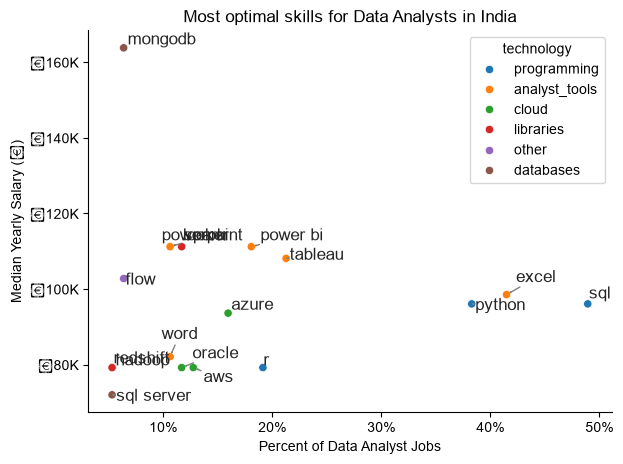

In [40]:
from adjustText import adjust_text
from matplotlib.ticker import PercentFormatter

#df_plot.plot(kind='scatter', x='skill_percent', y='median_salary')
sns.scatterplot(
    data=df_plot,
    x='skill_percent',
    y='median_salary',
    hue='technology'
)
sns.despine()
sns.set_theme(style= 'ticks')
# Prepare texts for adjustText
texts = []
for i, txt in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(df_DA_skills_high_demand['skill_percent'].iloc[i], df_DA_skills_high_demand['median_salary'].iloc[i], txt))

# Adjust text to avoid overlap
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray'))

# Set axis labels, title, and legend
plt.xlabel('Percent of Data Analyst Jobs')
plt.ylabel('Median Yearly Salary (₹)')
plt.title('Most optimal skills for Data Analysts in India')

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'₹{int(y/1000)}K'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))

# Adjust layout and display plot
plt.tight_layout()
plt.show()